# 04 Monte Carlo coverage check

Owner: Ma Tianjiao (B2, B3).

Coverage and width of both intervals on simulated series with known mean zero.

**Why this notebook exists.** On real data we never know the true mean, so we cannot see whether an interval is right.
Here we simulate data whose **true mean is 0** and count how often each 95% interval contains 0. A correct method should hit about 95%.

Five data-generating processes (DGPs), all with $n = 2{,}557$, mean 0, SD 0.024:

| # | DGP | What it isolates |
|---|---|---|
| 1 | i.i.d. normal | control: every t-test assumption holds |
| 2 | i.i.d. $t_3$ | heavy tails only |
| 3 | AR(1), $\phi = -0.11$ | negative autocorrelation, same $\rho_1$ as our real $d$ |
| 4 | AR(1), $\phi = +0.2$ | positive autocorrelation |
| 5 | GARCH(1,1), $\alpha = 0.10, \beta = 0.85$ | volatility clustering only |

Each DGP is repeated $R$ times; each time we compute `t_test_mean()` (B1) and Deng's `mbb_ci()` (A3) with $\ell = 14$, $B = 999$.

## 0 · Setup

In [1]:
import sys
from pathlib import Path

# Run from either the repo root or notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src import config
from src.data import load_daily
from src.strategy import build_series

FIG_DIR = config.FIG_DIR
TAB_DIR = config.TAB_DIR
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

# Two fixed colours: blue = t-test, orange = block bootstrap
C_T, C_BOOT, C_GREY = "#2a78d6", "#eb6834", "#8a8a85"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
})
pd.options.display.float_format = "{:.6g}".format

rng = np.random.default_rng(config.SEED)
import time

from src.classical import t_test_mean, ar1_t_coverage
from src.bootstrap import mbb_ci

**Config.** `N_SAMPLE`, `BLOCK_LENGTH`, `ALPHA`, `SEED` come from `src/config.py`. The simulation settings (SD, R, B, DGP parameters) are fixed in the task pack.
If the run is too slow, set `R = 500` and say so in the text below the results.

In [2]:
N = config.N_SAMPLE           # 2,557
L = config.BLOCK_LENGTH       # 14
LEVEL = 1 - config.ALPHA      # 0.95
SEED = config.SEED            # 607

SD = 0.024                    # target SD of every DGP
R = 1_000                     # replications per DGP (500 if too slow)
B_MC = 999                    # bootstrap draws per replication (smaller than 9,999 to save time)

PHI_NEG, PHI_POS = -0.11, 0.20
GARCH_ALPHA, GARCH_BETA = 0.10, 0.85
T_DF = 3

## 1 · Data-generating processes

Each function returns an $R \times n$ array: one simulated series per row.

- **$t_3$**: a $t_\nu$ variable has variance $\nu/(\nu-2) = 3$, so we divide by $\sqrt 3$ before scaling to SD 0.024.
- **AR(1)**: $x_t = \phi x_{t-1} + e_t$. Stationary variance is $\sigma_e^2/(1-\phi^2)$, so $\sigma_e = 0.024\sqrt{1-\phi^2}$. The first value is drawn from the stationary distribution.
- **GARCH(1,1)**: $x_t = \sqrt{h_t} z_t$, $h_t = \omega + \alpha x_{t-1}^2 + \beta h_{t-1}$. Unconditional variance is $\omega/(1-\alpha-\beta)$, so $\omega = 0.024^2 (1-\alpha-\beta)$. A 500-day burn-in is dropped.

In [3]:
def sim_iid_normal(rng, R, n):
    return SD * rng.standard_normal((R, n))


def sim_iid_t(rng, R, n, df=T_DF):
    return SD * rng.standard_t(df, size=(R, n)) / np.sqrt(df / (df - 2))


def sim_ar1(rng, R, n, phi):
    sd_e = SD * np.sqrt(1 - phi ** 2)
    e = sd_e * rng.standard_normal((R, n))
    x = np.empty((R, n))
    x[:, 0] = SD * rng.standard_normal(R)          # stationary start
    for t in range(1, n):
        x[:, t] = phi * x[:, t - 1] + e[:, t]
    return x


def sim_garch11(rng, R, n, alpha=GARCH_ALPHA, beta=GARCH_BETA, burn=500):
    omega = SD ** 2 * (1 - alpha - beta)
    h = np.full(R, SD ** 2)
    x = np.empty((R, n + burn))
    for t in range(n + burn):
        x[:, t] = np.sqrt(h) * rng.standard_normal(R)
        h = omega + alpha * x[:, t] ** 2 + beta * h
    return x[:, burn:]


DGPS = {
    "1 iid normal":        lambda rng: sim_iid_normal(rng, R, N),
    "2 iid t(3)":          lambda rng: sim_iid_t(rng, R, N),
    "3 AR(1) phi=-0.11":   lambda rng: sim_ar1(rng, R, N, PHI_NEG),
    "4 AR(1) phi=+0.2":    lambda rng: sim_ar1(rng, R, N, PHI_POS),
    "5 GARCH(1,1)":        lambda rng: sim_garch11(rng, R, N),
}

### 1a · Sanity check of the simulated data

Before trusting coverage numbers, check that each DGP has what it is supposed to have: mean ≈ 0, SD ≈ 0.024, the right $\rho_1$, heavy tails only where intended, and $\rho_1(|x|) > 0$ only for GARCH.

In [4]:
def lag1_corr(X):
    Xc = X - X.mean(axis=1, keepdims=True)
    return (Xc[:, 1:] * Xc[:, :-1]).sum(axis=1) / (Xc ** 2).sum(axis=1)


rng = np.random.default_rng(SEED)
sims = {name: make(rng) for name, make in DGPS.items()}

check = pd.DataFrame({
    name: {
        "mean": X.mean(),
        "SD": X.std(axis=1, ddof=1).mean(),
        "rho_1(x)": lag1_corr(X).mean(),
        "rho_1(|x|)": lag1_corr(np.abs(X)).mean(),
        "excess kurtosis": stats.kurtosis(X, axis=1).mean(),
    }
    for name, X in sims.items()
}).T
check.index.name = "DGP"
check

,mean,SD,rho_1(x),rho_1(|x|),excess kurtosis
DGP,,,,,
1 iid normal,1.15715e-05,0.0239862,3.17468e-05,-0.00112173,-0.0035337
2 iid t(3),-9.41693e-06,0.0238519,0.000329663,-0.000586344,45.4506
3 AR(1) phi=-0.11,1.10707e-05,0.0240048,-0.110176,0.0100274,-0.00722141
4 AR(1) phi=+0.2,-2.95095e-05,0.0240049,0.200111,0.0369488,-0.001527
"5 GARCH(1,1)",-3.57278e-05,0.0240343,0.00128947,0.14348,0.701612


## 2 · Coverage experiment

For every simulated series: does the 95% interval contain the true mean 0? Coverage = share of the $R$ replications where it does.
The t interval uses the $t_{n-1}$ critical value; the bootstrap interval is the percentile interval from `mbb_ci()`.

In [5]:
rows = []
t0 = time.time()
for name, X in sims.items():
    for i in range(X.shape[0]):
        x = X[i]
        tt = t_test_mean(x, LEVEL)
        bb = mbb_ci(x, L, B_MC, LEVEL)
        rows.append((name, i, "t-test", tt["t_lo"], tt["t_hi"]))
        rows.append((name, i, "block bootstrap", bb["pct_lo"], bb["pct_hi"]))
    print(f"{name:<20} done   ({time.time() - t0:5.0f} s)")

reps = pd.DataFrame(rows, columns=["DGP", "rep", "method", "lo", "hi"])
reps["covers"] = (reps["lo"] <= 0) & (reps["hi"] >= 0)
reps["width"] = reps["hi"] - reps["lo"]

1 iid normal         done   (   18 s)


2 iid t(3)           done   (   36 s)


3 AR(1) phi=-0.11    done   (   54 s)


4 AR(1) phi=+0.2     done   (   72 s)


5 GARCH(1,1)         done   (   91 s)


In [6]:
THEORY_T = {
    "1 iid normal": LEVEL,
    "2 iid t(3)": LEVEL,
    "3 AR(1) phi=-0.11": ar1_t_coverage(PHI_NEG, LEVEL),
    "4 AR(1) phi=+0.2": ar1_t_coverage(PHI_POS, LEVEL),
    "5 GARCH(1,1)": LEVEL,
}

cov = (reps.groupby(["DGP", "method"], sort=False)
           .agg(coverage=("covers", "mean"), mean_width=("width", "mean"), R=("covers", "size"))
           .reset_index())
cov["mc_se"] = np.sqrt(cov["coverage"] * (1 - cov["coverage"]) / cov["R"])
cov["theory (t-test)"] = np.where(cov["method"] == "t-test", cov["DGP"].map(THEORY_T), np.nan)
cov.to_csv(TAB_DIR / "04_coverage.csv", index=False)
cov

,DGP,method,coverage,mean_width,R,mc_se,theory (t-test)
0,1 iid normal,t-test,0.953,0.00186029,1000,0.00669261,0.95
1,1 iid normal,block bootstrap,0.95,0.00183952,1000,0.00689202,NaN
2,2 iid t(3),t-test,0.953,0.00184987,1000,0.00669261,0.95
3,2 iid t(3),block bootstrap,0.949,0.00182723,1000,0.00695694,NaN
4,3 AR(1) phi=-0.11,t-test,0.96,0.00186173,1000,0.00619677,0.971392
5,3 AR(1) phi=-0.11,block bootstrap,0.938,0.00165891,1000,0.00762601,NaN
6,4 AR(1) phi=+0.2,t-test,0.89,0.00186173,1000,0.00989444,0.890469
7,4 AR(1) phi=+0.2,block bootstrap,0.941,0.00222359,1000,0.00745111,NaN
8,"5 GARCH(1,1)",t-test,0.944,0.00186402,1000,0.00727076,0.95
9,"5 GARCH(1,1)",block bootstrap,0.94,0.00184773,1000,0.00750999,NaN


`mc_se` is the Monte Carlo standard error of the coverage estimate itself: with $R = 1{,}000$ and coverage near 0.95 it is about 0.007, so differences under ~1.5 percentage points are noise.

**Expected (task pack):** t interval ≈ 95% for DGPs 1, 2, 5; ≈ 97% for $\phi=-0.11$; ≈ 89% for $\phi=+0.2$. If the run is far off, check the code before writing anything.

In [7]:
t_rows = cov[cov["method"] == "t-test"].set_index("DGP")
gap = (t_rows["coverage"] - t_rows["theory (t-test)"]).abs()
print("max |simulated - theory| for the t interval:", f"{gap.max():.3f}")
print("within 3 MC SEs:", bool((gap <= 3 * t_rows["mc_se"]).all()))

max |simulated - theory| for the t interval: 0.011
within 3 MC SEs: True


## 3 · Coverage plot

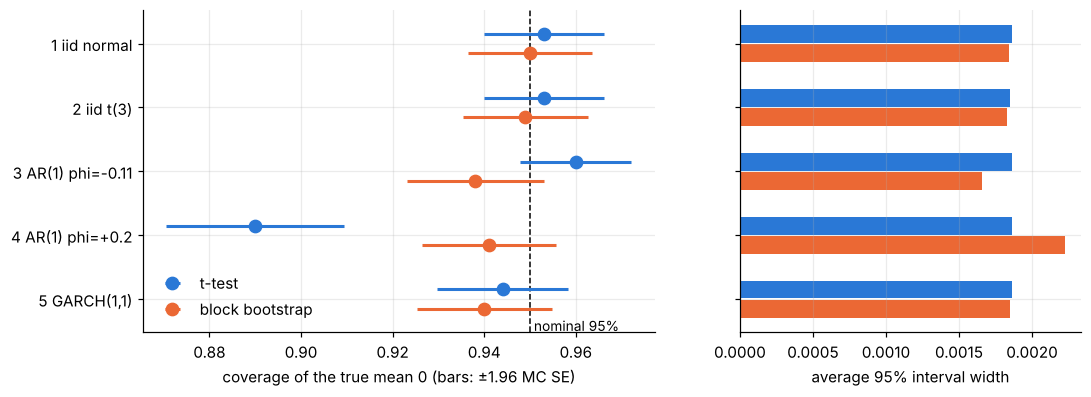

In [8]:
dgp_order = list(DGPS)
y = np.arange(len(dgp_order))
offset = {"t-test": -0.15, "block bootstrap": 0.15}
colour = {"t-test": C_T, "block bootstrap": C_BOOT}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True, gridspec_kw={"width_ratios": [3, 2]})
ax = axes[0]
ax.axvline(LEVEL, color="black", lw=1, ls="--")
ax.text(LEVEL, len(dgp_order) - 0.45, " nominal 95%", va="bottom", fontsize=9)
for method in offset:
    sub = cov[cov["method"] == method].set_index("DGP").loc[dgp_order]
    ax.errorbar(sub["coverage"], y + offset[method], xerr=1.96 * sub["mc_se"],
                fmt="o", ms=8, color=colour[method], ecolor=colour[method], elinewidth=2, capsize=0, label=method)
ax.set_yticks(y, dgp_order)
ax.invert_yaxis()
ax.set_xlabel("coverage of the true mean 0 (bars: ±1.96 MC SE)")
ax.legend(frameon=False, loc="lower left")

ax = axes[1]
for method in offset:
    sub = cov[cov["method"] == method].set_index("DGP").loc[dgp_order]
    ax.barh(y + offset[method], sub["mean_width"], height=0.28, color=colour[method], label=method)
ax.set_xlabel("average 95% interval width")
fig.savefig(FIG_DIR / "04_coverage.png")
plt.show()

<!-- DRAFT (AI-assisted): check every number, rewrite in your own words, then delete this line -->
**Interpretation.** The t interval keeps its 95% whenever $d$ has no linear autocorrelation: 95.3% for i.i.d. normal, 95.3% with $t_3$ heavy tails and 94.4% under GARCH volatility clustering.
It misses only when the series itself is autocorrelated, and the direction follows the sign of $\phi$.
With $\phi = -0.11$ it over-covers (96.0%; theory 97.1%), so it is conservative and wider than it needs to be. With $\phi = +0.2$ it under-covers badly (89.0%; theory 89.0%), so it is over-confident.
The block bootstrap repairs the positive case (94.1%) by widening the interval. In the negative case it gives a narrower interval (average width about 0.0017 vs 0.0019) with 93.8% coverage, slightly below nominal, which is typical of the moving-block bootstrap in finite samples.
In the i.i.d. cases it costs almost nothing (95.0% and 94.9%, similar widths).
Heavy tails and volatility clustering alone do not break the CI of the mean, exactly as section 4 of notebook 02 predicted.

## 4 · Which DGP looks most like our real $d$?

Same statistics as the sanity table, computed on the real series.

In [9]:
d = build_series(load_daily())["d"].to_numpy()
real = pd.Series({
    "mean": d.mean(),
    "SD": d.std(ddof=1),
    "rho_1(x)": lag1_corr(d[None, :])[0],
    "rho_1(|x|)": lag1_corr(np.abs(d)[None, :])[0],
    "excess kurtosis": stats.kurtosis(d),
}, name="real d")
compare = pd.concat([check, real.to_frame().T])
compare.to_csv(TAB_DIR / "04_dgp_vs_real.csv")
compare

,mean,SD,rho_1(x),rho_1(|x|),excess kurtosis
1 iid normal,1.15715e-05,0.0239862,3.17468e-05,-0.00112173,-0.0035337
2 iid t(3),-9.41693e-06,0.0238519,0.000329663,-0.000586344,45.4506
3 AR(1) phi=-0.11,1.10707e-05,0.0240048,-0.110176,0.0100274,-0.00722141
4 AR(1) phi=+0.2,-2.95095e-05,0.0240049,0.200111,0.0369488,-0.001527
"5 GARCH(1,1)",-3.57278e-05,0.0240343,0.00128947,0.14348,0.701612
real d,-0.000207795,0.0240021,-0.112745,0.36245,82.8504


<!-- DRAFT (AI-assisted): check every number, rewrite in your own words, then delete this line -->
**Interpretation.** Real $d$ mixes several features: $\rho_1 = -0.11$ like DGP 3; volatility clustering stronger than our GARCH DGP ($\rho_1(|d|) = 0.36$ vs 0.14); very heavy tails (excess kurtosis 83, mostly from 12 March 2020); and 55% exact zeros, which no DGP has.
The feature that matters for the CI of the mean is linear autocorrelation, and on that dimension real $d$ looks like DGP 3.
So on the real data we expect the t interval to be conservative (wider than needed, coverage above 95%) and the block-bootstrap interval to be closer to the right width, perhaps slightly below 95%.
On our data both intervals contain 0, so the main conclusion does not depend on which one we trust.